# Laboratorium 6 — Warstwa łącząca (pooling) i pełna CNN

**Cel:** zrozumieć pooling (max, average, global), porównać go ze splotem z krokiem i złożyć kompletną CNN. Na koniec porównamy warianty poolingu pod kątem accuracy i liczby parametrów.

## 0. Instalacja zależności

In [ ]:
!pip install torch torchvision matplotlib

## Import bibliotek i wybór urządzenia

In [1]:
import time, urllib.request
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.14.1+cu130 | urządzenie: cuda


## 1. Pełna CNN z konfigurowalnym poolingiem

Blok: splot → BN → ReLU → **redukcja**.  
Redukcję realizujemy jako max pooling, average pooling albo **splot z krokiem** (uczony). Na końcu GAP + warstwa gęsta.

In [2]:
class CNN(nn.Module):
    def __init__(self, n_classes=10, pool="max"):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            if pool == "max":
                layers.append(nn.MaxPool2d(2))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(2))
            elif pool == "stride":
                layers += [nn.Conv2d(cout, cout, 3, stride=2, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            return nn.Sequential(*layers)
        self.features = nn.Sequential(block(1, 32), block(32, 64))  # 28 -> 14 -> 7
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def count(m): return sum(p.numel() for p in m.parameters())

for p in ["max", "avg", "stride"]:
    m = CNN(pool=p)
    x = torch.randn(2,1,28,28)
    out = m(x)
    m.eval()

    with torch.no_grad():
      fmap = m.features(x)

    print(f"pool={p:6} | parametry {count(m):>7,} | Mapa przed GAP {tuple(fmap.shape[1:])} | wyjście {tuple(out.shape)}")

pool=max    | parametry  19,658 | Mapa przed GAP (64, 7, 7) | wyjście (2, 10)
pool=avg    | parametry  19,658 | Mapa przed GAP (64, 7, 7) | wyjście (2, 10)
pool=stride | parametry  66,026 | Mapa przed GAP (64, 7, 7) | wyjście (2, 10)


## 2. Eksperyment: warianty poolingu na FashionMNIST

Trenujemy trzy warianty tyle samo epok i porównujemy accuracy oraz liczbę parametrów. (FashionMNIST — szybki zbiór; wnioski przenoszą się na inne zbiory.)

In [3]:
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
train_ds = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 165kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.08MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.2MB/s]


In [5]:
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item()
            total += yb.numel()
    return correct/total

def train(model, epochs=6):
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    hist = {'test_accs': [], 'train_accs': []}
    for e in range(epochs):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()
        hist['test_accs'].append(evaluate(model, test_dl))
        hist['train_accs'].append(evaluate(model, train_dl))
    return hist

In [6]:
results = {}
for p in ["max", "avg", "stride"]:
    torch.manual_seed(0)
    m = CNN(pool=p)
    hist = train(m, epochs=6)
    results[p] = (hist, count(m))
    print(f"pool={p:6} | best acc {max(hist['test_accs'])*100:.2f}% | last acc {hist['test_accs'][-1]*100:.2f}% | parametry {count(m):,}")

pool=max    | best acc 81.86% | last acc 81.85% | parametry 19,658
pool=avg    | best acc 78.39% | last acc 78.39% | parametry 19,658
pool=stride | best acc 89.37% | last acc 89.37% | parametry 66,026


## 3. Porównanie - krzywe i tabela

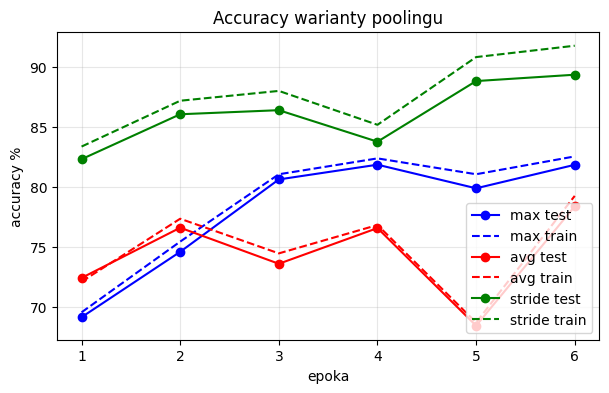

In [33]:
colors = {"max": "blue", "avg": "red", "stride": "green"}
plt.figure(figsize=(7,4))
for p,(hist,_) in results.items():
    plt.plot([a*100 for a in hist['test_accs']], "o-", color=colors[p], label=f"{p} test")
    plt.plot([a*100 for a in hist['train_accs']], "--", color=colors[p], label=f"{p} train")
plt.xlabel("epoka"); plt.ylabel("accuracy %"); plt.legend(); plt.title("Accuracy warianty poolingu")
plt.xticks(range(6), range(1, 7)); plt.grid(alpha=0.3); plt.show()

In [32]:
print(f"{'pool':7} | {'parametry':>10} | {'best acc':>9} | {'last acc':>11} | {'przerwa train-test'}")
print('-'*67)
for p,(hist,n) in results.items():
    gap = hist["train_accs"][-1] - hist["test_accs"][-1]
    print(f"{p:>7} | {n:>10,} | {max(hist['test_accs'])*100:>9.2f}% | {hist['test_accs'][-1]*100:>9.2f}% | {gap*100:>10.2f} p.p.")

pool    |  parametry |  best acc |    last acc | przerwa train-test
-------------------------------------------------------------------
    max |     19,658 |     81.86% |     81.85% |       0.70 p.p.
    avg |     19,658 |     78.39% |     78.39% |       0.87 p.p.
 stride |     66,026 |     89.37% |     89.37% |       2.42 p.p.
